# 01 — Cleaning the data and first look at the market

**Data:** one CSV from [Inside Airbnb](https://insideairbnb.com/get-the-data/)
— the Barcelona snapshot of **17 September 2026**: 15,236 listings, 19 columns.
Details and download steps: [`data/README.md`](../data/README.md).

**In this notebook:** check what is in the file, remove listings that cannot
be analysed, and take a first look at two policy levers the data can see:
the **tourist-licence phase-out** and the **seasonal-rental rules**.

Each lever is read the same way: *what the rule says*, *what the data shows*,
*what the data cannot show*. No verdicts.

The cleaning rules live in [`src/cleaning.py`](../src/cleaning.py), with
tests in [`tests/test_cleaning.py`](../tests/test_cleaning.py).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config as cfg
from src import cleaning

sns.set_theme(style="whitegrid", palette="colorblind")
np.random.seed(cfg.SEED)

In [2]:
raw = cleaning.load_listings()
print(raw.shape)
raw.drop(columns=["license", "host_name"]).head(3)   # personal columns excluded on purpose

(15236, 19)


,id,name,host_id,host_profile_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
0,18674,Huge flat for 8 people close to Sagrada Familia,71615,1462508358342835057,Eixample,la Sagrada Família,41.40556,2.17262,Entire home/apt,274.0,1.0,60,2026-07-20,0.37,21,162,8
1,23197,CCIB Forum • Spacious 3BR • Large Balcony,90417,1462509351463595774,Sant Martí,el Besòs i el Maresme,41.41243,2.21975,Entire home/apt,408.0,3.0,102,2026-09-07,0.54,1,128,11
2,34981,VIDRE HOME PLAZA REAL on LAS RAMBLAS,73163,1462508447204147103,Ciutat Vella,el Barri Gòtic,41.37978,2.17623,Entire home/apt,546.0,1.0,314,2026-09-13,1.62,2,316,43


> **Privacy note:** under EU rules the `license` column can contain real
> host names and home addresses. This project never prints that raw text —
> `cleaning.regional_licence()` and `cleaning.national_licence()` turn it into
> safe categories, and those categories are all we ever use.

In [3]:
# How much is missing in each column?
raw.isna().sum().sort_values(ascending=False).head(6)

license                  5466
reviews_per_month        3301
last_review              3301
price                    2626
minimum_nights           2045
number_of_reviews_ltm       0
dtype: int64

Two columns have gaps that matter: `price` and `minimum_nights`.
Is either gap random? Check both against availability:

In [4]:
no_dates = raw["availability_365"] == 0

print(f"listings with zero available nights: {no_dates.sum():,}")
print(f"   share with no price:            {raw.loc[no_dates, 'price'].isna().mean():.1%}")
print(f"   share with no minimum stay:     {raw.loc[no_dates, 'minimum_nights'].isna().mean():.1%}")
print(f"listings WITH available nights:      {(~no_dates).sum():,}")
print(f"   share with no price:            {raw.loc[~no_dates, 'price'].isna().mean():.1%}")
print(f"   share with no minimum stay:     {raw.loc[~no_dates, 'minimum_nights'].isna().mean():.1%}")

listings with zero available nights: 3,499
   share with no price:            46.4%
   share with no minimum stay:     58.4%
listings WITH available nights:      11,737
   share with no price:            8.5%
   share with no minimum stay:     0.0%


Both gaps are **systematic, not random**: they sit almost entirely in
listings with nothing bookable. Every listing without a minimum stay has
zero open dates. Dropping them removes listings that are not really on the
market, not a random slice of the data.

## Lever 1 — Seasonal rentals: the 31-night line

**What the rule says.** In Catalonia a stay of **31 days or fewer** is tourist
use and needs a tourist licence (HUT). A longer stay is a *seasonal* let
(*lloguer de temporada*). Since January 2026 seasonal lets also fall under
the rent cap in stressed areas (see `POLICY_LEVERS` in `src/config.py`).

**What the data shows.** The most common minimum stays:

In [5]:
print(raw["minimum_nights"].value_counts().head(6).to_string())
print()
over_31 = raw["minimum_nights"] > cfg.MAX_TOURIST_NIGHTS
print(f"listings requiring more than {cfg.MAX_TOURIST_NIGHTS} nights: "
      f"{over_31.sum():,} ({over_31.mean():.1%} of all listings)")

minimum_nights
1.0     4525
32.0    2505
31.0    2504
2.0     2051
3.0      764
4.0      174

listings requiring more than 31 nights: 2,760 (18.1% of all listings)


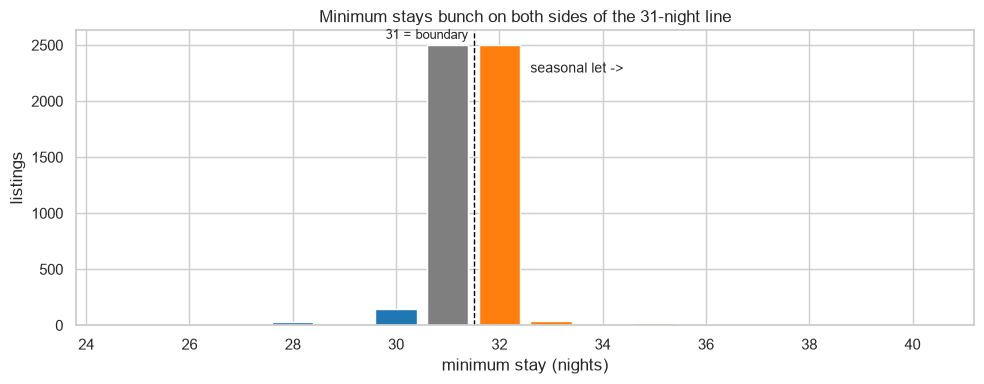

In [6]:
# Zoom in on the line: minimum stays from 25 to 40 nights
window = raw["minimum_nights"].between(25, 40)
counts = raw.loc[window, "minimum_nights"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
band_colors = {"tourist": "tab:blue", "boundary": "tab:gray", "seasonal": "tab:orange"}
colors = [band_colors[b] for b in cleaning.stay_band(pd.Series(counts.index))]
ax.bar(counts.index.astype(int), counts.values, color=colors)
ax.axvline(cfg.MAX_TOURIST_NIGHTS + 0.5, color="black", linestyle="--", linewidth=1)
ax.text(cfg.MAX_TOURIST_NIGHTS + 1.6, counts.max() * 0.9, "seasonal let ->", fontsize=10)
ax.text(cfg.MAX_TOURIST_NIGHTS - 0.4, counts.max() * 1.02, "31 = boundary", fontsize=9, ha="center")
ax.set_xlabel("minimum stay (nights)")
ax.set_ylabel("listings")
ax.set_title("Minimum stays bunch on both sides of the 31-night line")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "01_minimum_nights.png", dpi=150, bbox_inches="tight")

Minimum stays pile up on **31** and **32 nights**, with almost nothing
either side.

31 nights sits exactly on the legal line, and whether a 31-night booking
counts as "31 days or fewer" is ambiguous. So this project treats it as its
own **boundary** band: `tourist` (< 31) · `boundary` (= 31) · `seasonal` (> 31).

Hosts also *declare* which side they are on. The licence field carries
two declarations: a regional one (Catalan licence, or *Exempt - seasonal
rental*) and a national one (NRUA code, whose letters say tourist `TU` or
non-tourist `NT`). Do the declarations match the minimum stay?

In [7]:
feat = cleaning.add_columns(raw.dropna(subset=["minimum_nights"]))
bands = ["tourist", "boundary", "seasonal"]

def pct_by_band(column):
    table = pd.crosstab(feat[column], feat["stay_band"], normalize="columns") * 100
    return table[bands].round(1)

print("listings per band:", feat["stay_band"].value_counts()[bands].to_dict())
print()
print("regional licence, % of listings in each stay band:")
print(pct_by_band("regional_licence").to_string())
print()
print("national (NRUA) declaration, % of listings in each stay band:")
print(pct_by_band("national_licence").to_string())

listings per band: {'tourist': 7927, 'boundary': 2504, 'seasonal': 2760}

regional licence, % of listings in each stay band:
stay_band         tourist  boundary  seasonal
regional_licence                             
exempt_seasonal       0.0      55.7      47.0
hotel_or_hostel      10.4       0.0       0.0
hut                  67.9       0.8       1.7
missing              21.7      43.4      51.3
other                 0.0       0.0       0.0

national (NRUA) declaration, % of listings in each stay band:
stay_band         tourist  boundary  seasonal
national_licence                             
exempt                9.3       5.3       1.6
missing              31.9      49.5      43.0
nrua_seasonal         1.5      42.9      53.6
nrua_tourist         56.5       1.1       0.7
other                 0.8       1.2       1.1


The declarations line up with the minimum stay: tourist-band listings
mostly show an HUT licence and a tourist (`TU`) NRUA code; seasonal-band
listings mostly declare *Exempt - seasonal rental* and a non-tourist (`NT`)
code. **The boundary band behaves like the seasonal one** — hosts who set
exactly 31 nights almost never show an HUT licence.

A sizeable group shows **no regional licence at all** in the tourist band.
Who are they?

In [8]:
no_licence = feat[(feat["stay_band"] == "tourist") & (feat["regional_licence"] == "missing")]
print(f"tourist-band listings with no regional licence: {len(no_licence):,}")
print()
print(no_licence["room_type"].value_counts().to_string())
print()
print(f"with open dates:              {(no_licence['availability_365'] > 0).mean():.1%}")
print(f"reviewed in the last 12 months: {(no_licence['number_of_reviews_ltm'] > 0).mean():.1%}")

tourist-band listings with no regional licence: 1,718

room_type
Private room       1114
Entire home/apt     596
Hotel room            4
Shared room           4

with open dates:              51.6%
reviewed in the last 12 months: 34.4%


Most of them are **private rooms**, which in Barcelona follow a different
regime from whole tourist flats, and many show little recent activity. A
missing licence is therefore **not proof of an illegal listing**: it can be a
room in the host's own home, a listing Airbnb has already frozen, or a data
gap in what Inside Airbnb scraped.

**What the data cannot show.** Bunching at 31–32 nights is *consistent with*
hosts positioning just outside tourist rules, but it is equally consistent
with genuine month-long lets (students, posted workers, medical stays). The
file has asking terms only: not who stayed, for how long, or at what rent.
It also cannot show whether a seasonal let respects the rent cap — that needs
the flat's size and the official reference index, which are not here.

## Lever 2 — Tourist-licence phase-out

**What the rule says.** Barcelona's tourist-flat (HUT) licences are not to be
renewed when they expire in **November 2028** (Decret llei 3/2023).

**What the data shows.** How much of the current tourist market runs on an
HUT licence, and who holds those listings:

In [9]:
tourist = feat[feat["stay_band"] == "tourist"]
hut = tourist[tourist["has_hut"]]

print(f"tourist-band listings (< 31 nights):      {len(tourist):,}")
print(f"   with an HUT licence:                   {len(hut):,} ({len(hut) / len(tourist):.1%})")
print(f"   of those, entire homes:                {hut['is_entire_home'].mean():.1%}")
print(f"   of those, run by hosts with 5+ listings: {hut['is_professional'].mean():.1%}")

tourist-band listings (< 31 nights):      7,927
   with an HUT licence:                   5,383 (67.9%)
   of those, entire homes:                89.5%
   of those, run by hosts with 5+ listings: 65.7%


In [10]:
# Where are the HUT listings?
by_district = (hut.groupby("neighbourhood_group")["id"].count()
                  .sort_values()
                  .rename("HUT listings"))
by_district.to_frame().assign(share=lambda d: (d["HUT listings"] / d["HUT listings"].sum() * 100).round(1))

,HUT listings,share
neighbourhood_group,,
Nou Barris,17,0.3
Sant Andreu,42,0.8
Horta-Guinardó,111,2.1
Les Corts,127,2.4
Sarrià-Sant Gervasi,177,3.3
Sant Martí,524,9.7
Gràcia,526,9.8
Sants-Montjuïc,686,12.7
Ciutat Vella,805,15.0


**What the data cannot show.** One HUT licence is one dwelling, but one
dwelling can appear in several listings, and some licensed flats are not on
Airbnb at all. So listing counts are not a count of licences — the official
register (Ajuntament / Generalitat open data) is the right source for that.
The data also cannot show what happens to these flats after 2028: return to
long-term rent, move to seasonal lets, sale, or legal challenge.

## Cleaning

Three rules, from `src/cleaning.py`: keep listings with a usable price
(> 0 and ≤ 1000 EUR), a known minimum stay, and some sign of life (reviews or
open dates). Unlike the Berlin project, **seasonal listings are kept** —
they are one of the levers under study.

In [11]:
df = cleaning.clean_listings(raw)
df.to_csv(cfg.CLEAN_FILE, index=False)
print(f"\nsaved -> {cfg.CLEAN_FILE.name}")

start:                              15,236 listings
with a usable price (<= 1000 EUR):   12,311
known minimum stay:                 10,439
active (has reviews or open dates): 10,439



saved -> listings_clean.csv


In [12]:
# Headline numbers, by stay band
summary = (df.groupby("stay_band")
             .agg(listings=("id", "count"),
                  median_price=("price", "median"),
                  entire_homes=("is_entire_home", "mean"))
             .loc[["tourist", "boundary", "seasonal"]]
             .round(2))
summary

,listings,median_price,entire_homes
stay_band,,,
tourist,6399,245.0,0.77
boundary,1902,82.5,0.60
seasonal,2138,72.0,0.63


## Who supplies this market?

`calculated_host_listings_count` says how many Barcelona listings each host
runs — so we can see how concentrated the market is.

In [13]:
hosts = raw.dropna(subset=["host_id"]).groupby("host_id")["id"].count()

big = hosts[hosts >= cfg.PROFESSIONAL_MIN]
print(f"hosts in total:            {len(hosts):,}")
print(f"hosts with 5+ listings:    {len(big):,}  ({len(big) / len(hosts):.1%} of hosts)")
print(f"listings they control:     {big.sum():,}  ({big.sum() / len(raw):.1%} of the market)")
print(f"largest single host runs:  {hosts.max()} listings")

hosts in total:            4,586
hosts with 5+ listings:    585  (12.8% of hosts)
listings they control:     9,617  (63.1% of the market)
largest single host runs:  579 listings


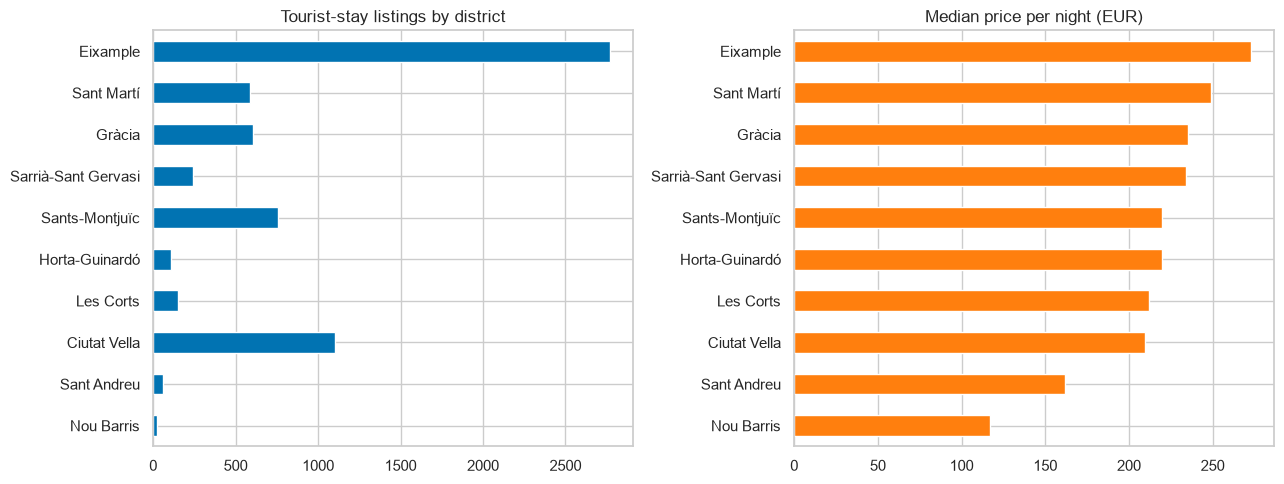

In [14]:
# Listings and median price by district (tourist stays only)
by_district = (df[df["stay_band"] == "tourist"]
                 .groupby("neighbourhood_group")
                 .agg(listings=("id", "count"), median_price=("price", "median"))
                 .sort_values("median_price"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_district["listings"].plot.barh(ax=axes[0], title="Tourist-stay listings by district")
by_district["median_price"].plot.barh(ax=axes[1], color="tab:orange",
                                      title="Median price per night (EUR)")
for ax in axes:
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "01_districts.png", dpi=150, bbox_inches="tight")

## What I found

1. **Gaps are systematic.** Missing prices (17%) and missing minimum stays
   (13%) sit almost entirely in listings with zero open dates.
2. **The market bunches on the 31-night line.** 2,504 listings ask exactly
   31 nights and 2,505 ask 32 — together a third of all listings, more than
   any other value except 1 night.
3. **31 nights behaves like seasonal, not tourist.** Only 0.8% of 31-night
   listings show an HUT licence (vs 67.9% below 31), and their median asking
   price is €82 a night, close to seasonal (€72) and far from tourist (€245).
4. **Declarations match the side.** 56.5% of tourist-band listings show a
   tourist (`TU`) NRUA code; 53.6% of seasonal-band listings show a
   non-tourist (`NT`) code. 21.7% of tourist-band listings show no regional
   licence, two thirds of them private rooms.
5. **The phase-out touches a concentrated, central slice.** 5,383 listings
   carry an HUT licence; 89.5% are entire homes, 65.7% belong to hosts with
   5+ listings, and 59% are in Eixample or Ciutat Vella.
6. **Supply is concentrated.** 12.8% of hosts run 5+ listings and control
   63.1% of the market (Berlin: 27%); the largest host runs 579.

**Next:** `02_statistics.ipynb` — how sure are we about these numbers, and
which differences are real?